In [66]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 25,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 30,
    'ytick.labelsize': 30,
    'legend.fontsize': 25,
})

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
})


sigma_ref = 0.0652,  dL_cap_marginal = 2.30,  dL_min = 1.11,  dL_cap = 1.11
Saved plots/newton_convergence_diagnostic_capped_w0.5_chi255.pdf


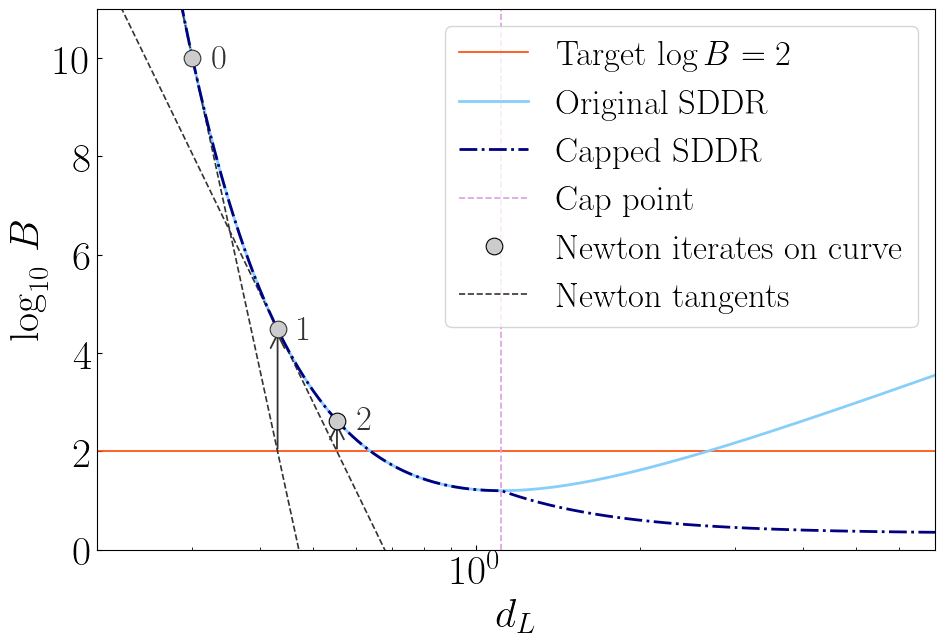

In [74]:
# --- Parameters ---
k = 4
dL_ref = 0.3
chi2_ref = 55
log10B_ref = 10
target_log10B = 2
prior_width = 0.5        # effective prior width per direction

ln10 = np.log(10)
C = log10B_ref - k * np.log10(dL_ref) - chi2_ref / (2 * ln10)

# Recover sigma_ref from the decomposition:
#   C = -k*log10(w) + k/2*log10(2pi) + k*log10(sigma_ref / dL_ref)
log10_sigma_over_dLref = (C + k * np.log10(prior_width)
                          - k / 2 * np.log10(2 * np.pi)) / k
sigma_ref = dL_ref * 10**log10_sigma_over_dLref
dL_cap_marginal = dL_ref * prior_width / sigma_ref

# --- Turning point (original curve minimum): chi2 = k ---
dL_min = dL_ref * np.sqrt(chi2_ref / k)

# Cap at whichever comes first: marginal hitting prior, or turning point
dL_cap = min(dL_cap_marginal, dL_min)
print(f'sigma_ref = {sigma_ref:.4f},  dL_cap_marginal = {dL_cap_marginal:.2f},  '
      f'dL_min = {dL_min:.2f},  dL_cap = {dL_cap:.2f}')

dL_hi = 10
dL_arr = np.geomspace(dL_ref * 0.5, dL_hi, 1000)

# --- chi2(dL) ---
chi2_arr = chi2_ref * (dL_ref / dL_arr)**2

# --- Original log10(B) ---
log10B_orig = C + k * np.log10(dL_arr) + chi2_arr / (2 * ln10)

# --- Capped log10(B): freeze log-det term at dL_cap ---
log10_dL_capped = np.minimum(np.log10(dL_arr), np.log10(dL_cap))
log10B_cap = C + k * log10_dL_capped + chi2_arr / (2 * ln10)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 7))

ax.axhline(target_log10B, color='orangered', lw=1.2,
            label=f'Target $\\log B = {target_log10B}$')
ax.plot(dL_arr, log10B_orig, color='lightskyblue', lw=2, label='Original SDDR', zorder=2)
ax.plot(dL_arr, log10B_cap, color='navy', lw=2, ls='-.',
         label='Capped SDDR', zorder=3)
ax.axvline(dL_cap, color='plum', ls='--', lw=1.2,
            label='Cap point')

# --- Two Newton steps on the original curve ---
def log10B_func(log10_dL):
    chi2 = chi2_ref * (dL_ref / 10**log10_dL)**2
    return C + k * log10_dL + chi2 / (2 * ln10)

def deriv_func(log10_dL):
    chi2 = chi2_ref * (dL_ref / 10**log10_dL)**2
    return k - chi2

log10_dL_arr = np.log10(dL_arr)
newton_color = '0.8'
edge_color = '0.2'
newton_x = [np.log10(dL_ref)]
newton_y = [log10B_ref]

for i in range(2):
    xi, yi = newton_x[-1], newton_y[-1]
    si = deriv_func(xi)
    tangent = yi + si * (log10_dL_arr - xi)
    ax.plot(dL_arr, tangent, '--', color=edge_color, lw=1.2)
    ax.plot(10**xi, yi, 'o', color=newton_color, ms=12, zorder=5,
             markeredgecolor=edge_color, markeredgewidth=0.8)
    label_transform = mpl.transforms.offset_copy(
        ax.transData, fig=fig, x=20, y=-0.5, units='points')
    ax.text(10**xi, yi, f'{i}', color=edge_color, fontsize=25,
            ha='center', va='center', zorder=6, transform=label_transform)
    x_next = xi + (target_log10B - yi) / si
    ax.plot(10**x_next, target_log10B, 's', color=newton_color, ms=0,
             zorder=5, markeredgecolor=edge_color, markeredgewidth=0.8)
    ax.annotate('', xy=(10**x_next, log10B_func(x_next)),
                 xytext=(10**x_next, target_log10B),
                 arrowprops=dict(arrowstyle='->', color=edge_color,
                                 lw=1.3))
    newton_x.append(x_next)
    newton_y.append(log10B_func(x_next))

ax.plot(10**newton_x[-1], newton_y[-1], 'o', color=newton_color, ms=12,
         zorder=5, markeredgecolor='k', markeredgewidth=0.8)
label_transform = mpl.transforms.offset_copy(
    ax.transData, fig=fig, x=20, y=0, units='points')
ax.text(10**newton_x[-1], newton_y[-1],
        f'{len(newton_x) - 1}', color=edge_color,
        fontsize=25, ha='center', va='center', zorder=6,
        transform=label_transform)

ax.plot([], [], 'o', color=newton_color, ms=12, markeredgecolor='k',
         markeredgewidth=0.8, label='Newton iterates on curve')
ax.plot([], [], '--', color=edge_color, lw=1.2, label='Newton tangents')

ax.set_ylabel(r'$\log_{10}\, B$')
ax.set_xlabel(r'$d_L$')
ax.set_ylim(0, 11)
ax.set_xlim(0.2, 7)
ax.legend(loc='upper right')
ax.set_xscale('log')
ax.tick_params(direction='in', which='both')

plt.tight_layout()
label = f'capped_w{prior_width}_chi2{chi2_ref:.0f}'
plt.savefig(f'plots/newton_convergence_diagnostic_{label}.pdf')
print(f'Saved plots/newton_convergence_diagnostic_{label}.pdf')
